In [2]:
import pickle
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

2026-09-27 15:56:28.457007: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/mguerra1/miniconda3/envs/garmion/lib/python3.9/site-packages/cv2/../../lib64:
2026-09-27 15:56:28.457036: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


 # Traditional BG suppression
 Initially user draws a rectangle around the foreground region (foreground region should be completely inside the rectangle). Then algorithm segments it iteratively to get the best result. Done. Result can be refined with additional strokes.

 Reference work: Dress_Segmentation, cerlymarco @ MEDIUM

In [3]:
def grabcut(img):

    img = cv.resize(img,(224,224))
    
    mask = np.zeros(img.shape[:2],np.uint8)
    bgdModel = np.zeros((1,65),np.float64)
    fgdModel = np.zeros((1,65),np.float64)
    height, width = img.shape[:2]

    rect = (50,10,width-100,height-20)
    cv.grabCut(img,mask,rect,bgdModel,fgdModel,5,cv.GC_INIT_WITH_RECT)
    mask2 = np.where((mask==2)|(mask==0),0,1).astype('uint8')
    img2 = img*mask2[:,:,np.newaxis]
    img2[mask2 == 0] = (255, 255, 255)
    
    final = np.ones(img.shape,np.uint8)*0 + img2
    
    return mask, final

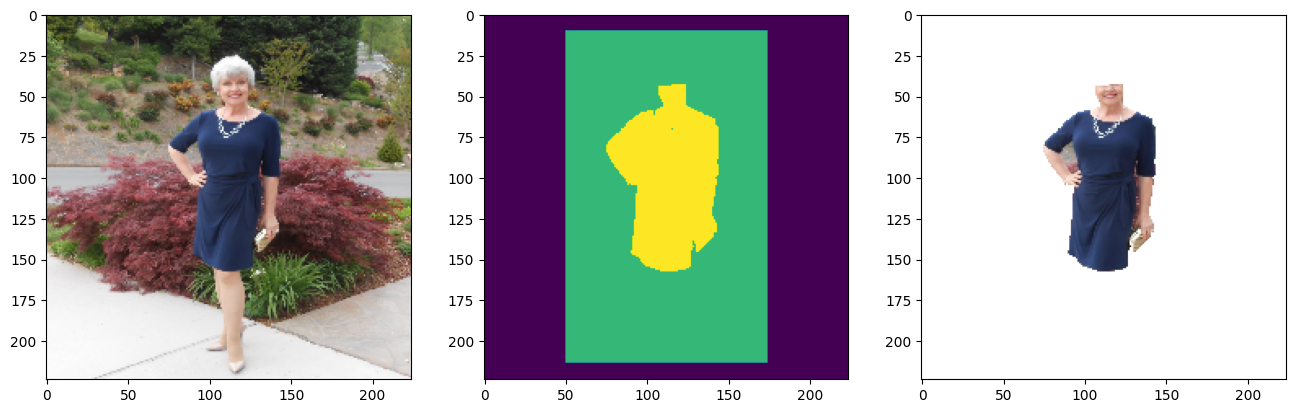

In [ ]:
### APPLY GRUBCUT ###
plt.figure(figsize=(16,8))
original = cv.imread('test_set/testGrabCut.jpg')
original = cv.resize(original,(224,224))

plt.subplot(1,3,1)
plt.imshow(cv.cvtColor(original, cv.COLOR_BGRA2RGB))
mask, final = grabcut(original)
plt.subplot(1,3,2)
plt.imshow(mask)
plt.subplot(1,3,3)
plt.imshow(cv.cvtColor(final, cv.COLOR_BGRA2RGB))

# Neural Garment Segmentation
We actually segment for background, skin and dress.

In [19]:
### LOAD PRETRAINED UNET ###
UNET = tf.keras.models.load_model('./trained_models/unet_one_sample_train_lol.h5')
UNET.summary()

# given Train_UNET.ipynb (chaotic...)
# +------------------+------------------+-------------------+-----------------------
# | True Pixel Class | Channel 0 (Skin) | Channel 1 (Dress) | Channel 2 (Background)
# +------------------+------------------+-------------------+-----------------------
# | Skin             | 1.0              | 0.0               | 0.0                   
# | Dress            | 0.0              | 1.0               | 1.0                   
# | Background       | 0.0              | 0.0               | 1.0                   
# +------------------+------------------+-------------------+-----------------------

Model: "functional_1"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, None, None,  0                                            
__________________________________________________________________________________________________
lambda (Lambda)                 (None, 224, 224, 3)  0           input_1[0][0]                    
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, 224, 224, 32) 896         lambda[0][0]                     
__________________________________________________________________________________________________
dropout (Dropout)               (None, 224, 224, 32) 0           conv2d[0][0]                     
_______________________________________________________________________________________

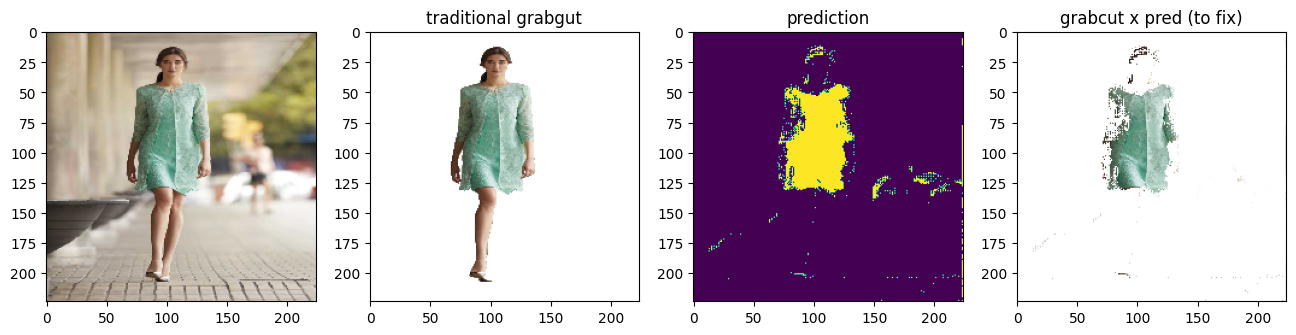

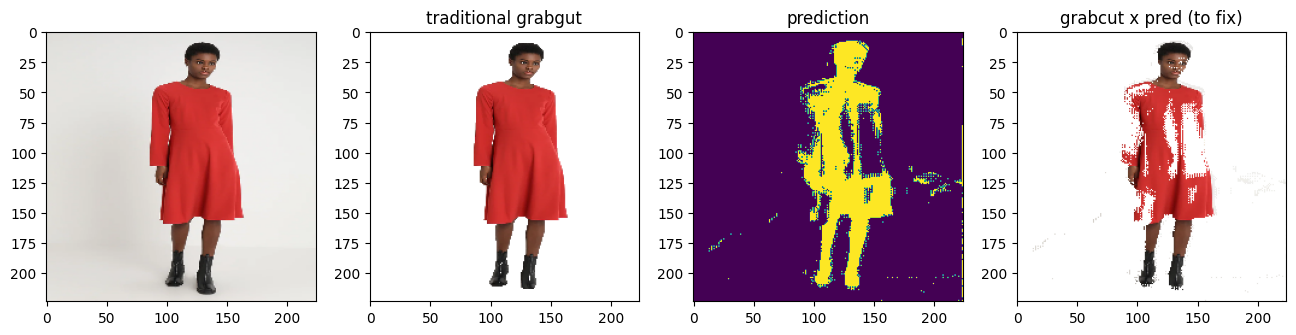

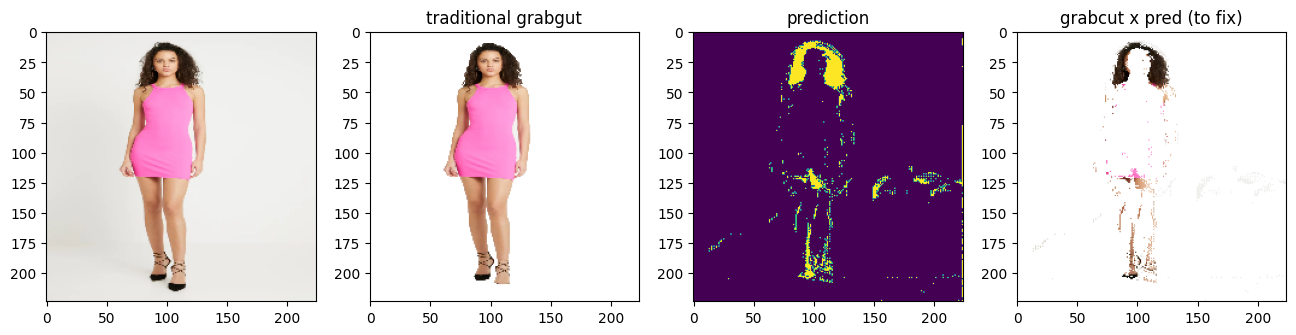

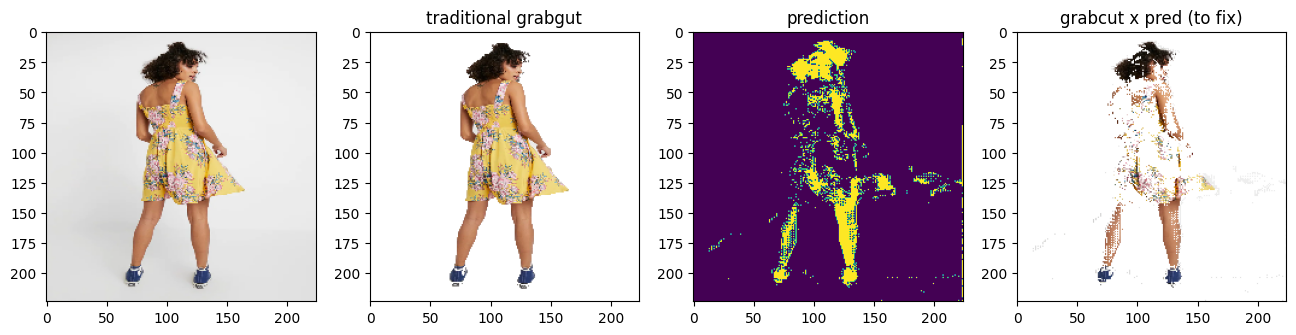

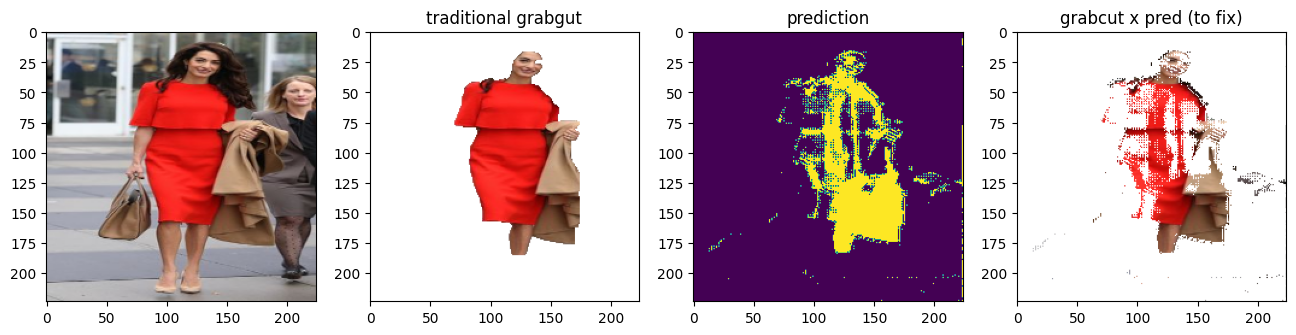

In [ ]:
for img_path in ['test_set/test1.jpg', 'test_set/test2.jpg', 'test_set/test3.jpg', 'test_set/test4.jpg', 'test_set/test5.jpg']:

    ### READ NEW IMAGE ###
    plt.figure(figsize=(16,8))
    img = cv.cvtColor(cv.imread(img_path), cv.COLOR_BGRA2RGB)
    plt.subplot(1,4,1)
    plt.imshow(cv.resize(img.copy(),(224,224)))

    ### IMAGE -> GRABCUT -> PREDICTION ###
    mask_test, test = grabcut(img)
    pred = UNET.predict(test[None,...])[0]
    plt.subplot(1,4,2)
    plt.title('traditional grabgut')
    plt.imshow(test)

    ## APPLY PIXEL TRESHOLD FOR MASK###
    CONFIDENCE_THRESHOLD = 0.50
    pred_dress = pred.copy()[:,:,1]
    pred_dress[pred_dress >= CONFIDENCE_THRESHOLD] = 1 # accuracy was technically 0.84
    pred_dress[pred_dress < CONFIDENCE_THRESHOLD] = 0

    plt.subplot(1,4,3)
    plt.title('prediction')
    plt.imshow(pred_dress)

    real_dress = (cv.resize(img.copy(),(224,224))*pred_dress[:,:,np.newaxis]).astype('int')
    real_dress[pred_dress == 0] = (255, 255, 255)
    plt.subplot(1,4,4)
    plt.title('grabcut x pred (to fix)')
    plt.imshow(real_dress.astype('uint8'))